In [59]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

## Data Collection

In [60]:
funds = ["FSPTX", "FSELX", "FSCSX", "FSPHX", "FBIOX", "FSMEX", "FPHAX", "FIDSX", "FSRBX", "FSPCX", "FSENX", "FSDAX", "FSRFX", "FSCPX", "FSAVX", "FSRPX", "FDFAX", "FSTCX", "FWRLX"]
prices = yf.download(tickers=funds + ["SPY", "XLK"], start="2015-01-01", end="2026-10-01", auto_adjust=False, progress=False)

In [61]:
prices = prices["Adj Close"]
prices

Ticker,FBIOX,FDFAX,FIDSX,FPHAX,FSAVX,FSCPX,FSCSX,FSDAX,FSELX,FSENX,...,FSPCX,FSPHX,FSPTX,FSRBX,FSRFX,FSRPX,FSTCX,FWRLX,SPY,XLK
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-02,11.000014,46.551399,4.670525,10.712301,20.123484,19.435740,4.505634,6.041415,2.884584,36.330261,...,26.004522,10.029356,4.799391,11.604661,42.423233,4.205565,28.825602,3.914888,169.267502,18.041683
2015-01-05,11.020169,46.056793,4.580222,10.622029,19.604450,19.080353,4.434748,5.946351,2.837291,34.780518,...,25.517300,9.970015,4.720869,11.296418,41.462181,4.124608,28.381540,3.837536,166.210541,17.766272
2015-01-06,10.810784,45.965549,4.512496,10.556832,19.371323,18.899740,4.365809,5.905756,2.785574,34.280083,...,25.207952,9.872950,4.676363,11.035933,40.682724,4.080832,28.109367,3.798860,164.645081,17.552063
2015-01-07,11.174009,46.618633,4.551346,10.757439,19.718809,19.243483,4.386452,5.963821,2.811093,34.280083,...,25.455431,10.130101,4.708274,11.118417,40.833302,4.156613,28.276485,3.833239,166.696701,17.700695
2015-01-08,11.334733,47.358150,4.610148,10.963058,20.066299,19.523130,4.462013,6.089202,2.889349,35.038815,...,25.803450,10.312268,4.812407,11.292076,41.719051,4.208390,28.682350,3.893402,169.654785,18.089767
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-24,29.000000,91.109657,16.469999,34.869999,51.939999,61.090000,24.660000,25.860001,63.730000,90.510002,...,91.459999,29.990000,58.070000,36.110001,112.410004,16.629999,67.925964,15.230000,767.179993,194.710007
2026-09-25,28.920000,91.507607,16.610001,35.000000,52.450001,61.259998,24.530001,26.059999,64.379997,89.889999,...,91.919998,29.959999,58.459999,36.509998,113.059998,16.719999,67.727005,15.320000,771.349976,196.270004
2026-09-28,28.969999,91.855804,16.410000,34.990002,51.380001,60.459999,24.299999,25.490000,63.840000,89.889999,...,91.730003,30.139999,57.889999,36.000000,112.720001,16.680000,66.851562,15.060000,765.609985,194.529999


In [62]:
log_returns = np.log(prices).diff().dropna()
market_log_returns = log_returns["SPY"]
xlk_log_returns = log_returns["XLK"]
log_returns = log_returns[funds]
print(log_returns)

Ticker         FSPTX     FSELX     FSCSX     FSPHX     FBIOX     FSMEX  \
Date                                                                     
2015-01-05 -0.016496 -0.016531 -0.015858 -0.005934  0.001831  0.003872   
2015-01-06 -0.009472 -0.018396 -0.015667 -0.009783 -0.019183 -0.008019   
2015-01-07  0.006801  0.009119  0.004717  0.025713  0.033046  0.019293   
2015-01-08  0.021876  0.027458  0.017079  0.017823  0.014281  0.018678   
2015-01-09 -0.005074  0.000942 -0.009472 -0.004426  0.000434 -0.004009   
...              ...       ...       ...       ...       ...       ...   
2026-09-24  0.000517 -0.004071 -0.005258  0.015119  0.004839  0.022781   
2026-09-25  0.006694  0.010148 -0.005286 -0.001001 -0.002762 -0.000176   
2026-09-28 -0.009798 -0.008423 -0.009421  0.005990  0.001727  0.010156   
2026-09-29 -0.004328  0.010285  0.001234 -0.001993 -0.003112  0.001914   
2026-09-30  0.005364  0.000465  0.011849 -0.007676 -0.001733 -0.008206   

Ticker         FPHAX     FIDSX     FS

## Performace Summary

### Part 1

In [63]:
mean_returns = log_returns.mean() * 252
volatilities = log_returns.std() * np.sqrt(252)
sharpe_ratio = mean_returns / volatilities

absolute = pd.DataFrame({
    "Mean Return": mean_returns,
    "Volatility": volatilities,
    "Sharpe Ratio": sharpe_ratio,
})

summary_abs = absolute.describe().loc[["min", "25%", "mean", "50%", "75%", "max"]]
summary_abs.index = ["Min", "Q1", "Mean", "Median", "Q3", "Max"]
summary_abs.round(4)

,Mean Return,Volatility,Sharpe Ratio
Min,0.0562,0.1482,0.2480
Q1,0.0826,0.1941,0.3823
Mean,0.1119,0.2263,0.4927
Median,0.0995,0.2181,0.4868
Q3,0.1158,0.2441,0.5612
Max,0.2653,0.3431,0.8405


### Part 2

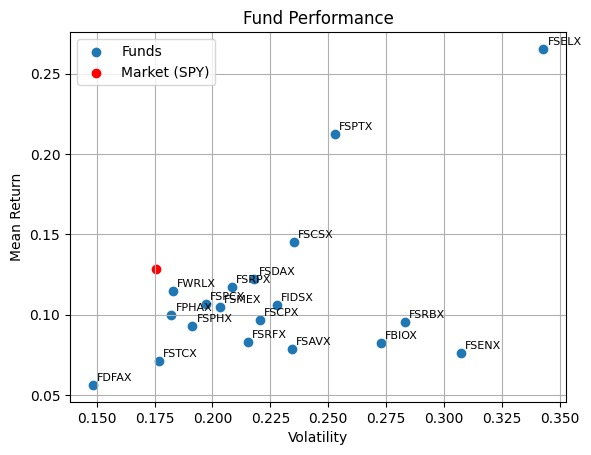

0.7313612772108294


,Mean Return,Volatility,Sharpe Ratio
Ticker,,,
FSPTX,0.212654,0.253010,0.840498
FSELX,0.265296,0.343075,0.773289
FSCSX,0.144971,0.235144,0.616521


In [64]:
market_mean_return = market_log_returns.mean() * 252
market_volatility = market_log_returns.std() * np.sqrt(252)

fund_metrics = pd.DataFrame({
    "Mean Return": mean_returns,
    "Volatility": volatilities,
})
plt.scatter(fund_metrics["Volatility"], fund_metrics["Mean Return"], label="Funds")
for t in fund_metrics.index:
    plt.annotate(t, (fund_metrics.loc[t, "Volatility"], fund_metrics.loc[t, "Mean Return"]),
                 fontsize=8, xytext=(3, 3), textcoords="offset points")
plt.scatter(market_volatility, market_mean_return, color="red", marker="o", label="Market (SPY)")
plt.xlabel("Volatility")
plt.ylabel("Mean Return")
plt.title("Fund Performance")
plt.grid(True)
plt.legend()
plt.show()

indices = fund_metrics["Mean Return"] > market_mean_return
outperforms_market = fund_metrics[indices].copy()
outperforms_market

market_sharpe_ratio = market_mean_return / market_volatility
print(market_sharpe_ratio)
outperforms_market["Sharpe Ratio"] = outperforms_market["Mean Return"] / outperforms_market["Volatility"]
outperforms_market

Only the three technology-oriented funds, Software (FSCSX, 14.5%), Technology (FSPTX, 21.3%) and Semiconductors (FSLX, 26.5%), outperform SPY's 12.9% mean return, but each does so with higher volatility (23.5%-34.3% vs. 17.6% for SPY).

### Part 3

#### (a)

In [65]:
combined = log_returns.copy()
combined["SPY"] = market_log_returns
covariances = combined.cov() * 252
betas = (covariances["SPY"] / covariances.loc["SPY", "SPY"]).drop("SPY")

alphas = mean_returns - betas * market_mean_return
alphas

treynor = (mean_returns) / betas
treynor

tracking_error = log_returns.sub(market_log_returns, axis=0)
tracking_error = tracking_error.std() * np.sqrt(252)

information_ratio = (mean_returns - market_mean_return) / tracking_error
information_ratio

relative = pd.DataFrame({
    "Jensen's Alpha": alphas,
    "Beta": betas,
    "Treynor Ratio": treynor,
    "Tracking Error": tracking_error,
    "Information Ratio": information_ratio,
})

summary = relative.describe().loc[["min", "25%", "mean", "50%", "75%", "max"]]
summary.index = ["Min", "Q1", "Mean", "Median", "Q3", "Max"]
summary

,Jensen's Alpha,Beta,Treynor Ratio,Tracking Error,Information Ratio
Min,-0.062318,0.595044,0.071747,0.082447,-0.569804
Q1,-0.045769,0.878273,0.084866,0.123740,-0.298563
Mean,-0.016218,0.997018,0.110406,0.144635,-0.134738
Median,-0.015994,1.001509,0.109662,0.132159,-0.186634
Q3,-0.001411,1.107424,0.126945,0.142102,-0.136138
Max,0.064266,1.564427,0.169580,0.248289,0.682078


(b)

In [66]:
area = pd.Series({
    "FSPTX": "Technology", "FSELX": "Semiconductors", "FSCSX": "Software",
    "FSPHX": "Health Care", "FBIOX": "Biotechnology", "FSMEX": "Medical Technology",
    "FPHAX": "Pharmaceuticals", "FIDSX": "Financials", "FSRBX": "Banking",
    "FSPCX": "Insurance", "FSENX": "Energy", "FSDAX": "Aerospace/Defense",
    "FSRFX": "Transportation", "FSCPX": "Consumer Discretionary", "FSAVX": "Automotive",
    "FSRPX": "Retailing", "FDFAX": "Consumer Staples", "FSTCX": "Telecommunications",
    "FWRLX": "Wireless",
})

top5 = alphas.sort_values(ascending=False).index[:5]
top5_table = pd.concat([area[top5].rename("Area"), relative.loc[top5, ["Jensen's Alpha", "Beta"]], absolute.loc[top5]], axis=1)
top5_table["Mean Return Rank"] = mean_returns.rank(ascending=False)[top5].astype(int)
top5_table["Sharpe Rank"] = sharpe_ratio.rank(ascending=False)[top5].astype(int)
top5_table.round(4)

,Area,Jensen's Alpha,Beta,Mean Return,Volatility,Sharpe Ratio,Mean Return Rank,Sharpe Rank
Ticker,,,,,,,,
FSELX,Semiconductors,0.0643,1.5644,0.2653,0.3431,0.7733,1,2
FSPTX,Technology,0.0469,1.2903,0.2127,0.2530,0.8405,2,1
FPHAX,Pharmaceuticals,0.0096,0.6996,0.0995,0.1822,0.5459,10,7
FSDAX,Aerospace/Defense,-0.0004,0.9546,0.1223,0.2181,0.5605,4,6
FSCSX,Software,-0.0008,1.1342,0.1450,0.2351,0.6165,3,4


### 4.

#### (a)

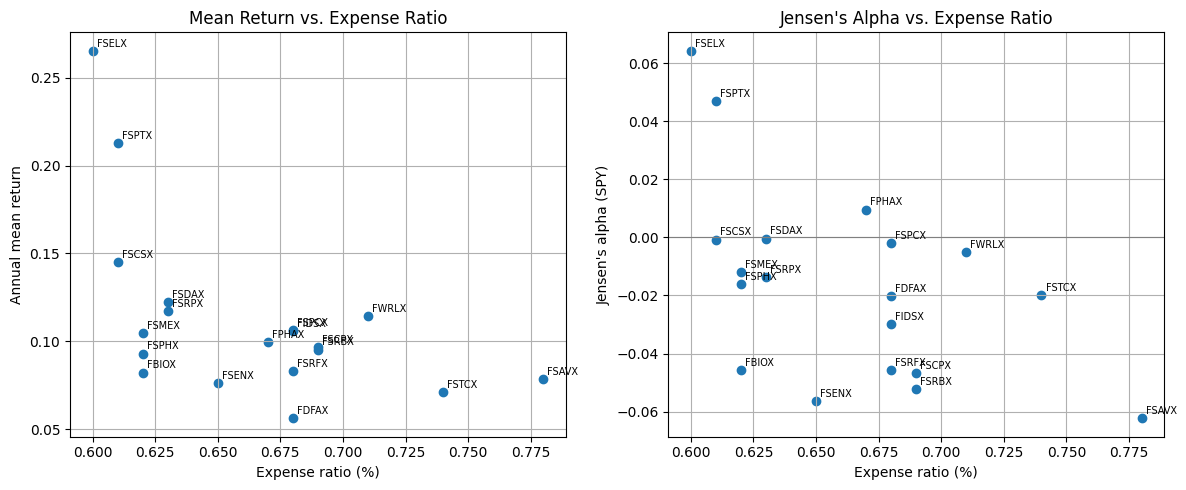

In [ ]:
expense = pd.Series({
    "FSPTX": 0.61, "FSELX": 0.60, "FSCSX": 0.61, "FSPHX": 0.62, "FBIOX": 0.62,
    "FSMEX": 0.62, "FPHAX": 0.67, "FIDSX": 0.68, "FSRBX": 0.69, "FSPCX": 0.68,
    "FSENX": 0.65, "FSDAX": 0.63, "FSRFX": 0.68, "FSCPX": 0.69, "FSAVX": 0.78,
    "FSRPX": 0.63, "FDFAX": 0.68, "FSTCX": 0.74, "FWRLX": 0.71,
})

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(expense[funds], mean_returns[funds])
ax[0].set_xlabel("Expense ratio (%)")
ax[0].set_ylabel("Annual mean return")
ax[0].set_title("Mean Return vs. Expense Ratio")
ax[0].grid(True)

ax[1].scatter(expense[funds], alphas[funds])
ax[1].axhline(0, color="gray", linewidth=0.8)
ax[1].set_xlabel("Expense ratio (%)")
ax[1].set_ylabel("Jensen's alpha (SPY)")
ax[1].set_title("Jensen's Alpha vs. Expense Ratio")
ax[1].grid(True)

for t in funds:
    ax[0].annotate(t, (expense[t], mean_returns[t]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax[1].annotate(t, (expense[t], alphas[t]), fontsize=7, xytext=(3, 3), textcoords="offset points")

plt.tight_layout()
plt.savefig("fig_1_4.png", dpi=300)
plt.show()

#### (b)

In [ ]:
print("Corr(ER, Mean): ", round(expense[funds].corr(mean_returns[funds]), 4))
print("Corr(ER, Alpha):", round(expense[funds].corr(alphas[funds]), 4))

Corr(ER, Mean):  -0.5501
Corr(ER, Alpha): -0.5391


### 5.

#### (a)

In [ ]:
xlk_mean_return = xlk_log_returns.mean() * 252

returns_xlk = log_returns[funds].copy()
returns_xlk["XLK"] = xlk_log_returns
cov_xlk = returns_xlk.cov() * 252
betas_xlk = (cov_xlk["XLK"] / cov_xlk.loc["XLK", "XLK"]).drop("XLK")

alphas_xlk = mean_returns - betas_xlk * xlk_mean_return
treynor_xlk = mean_returns / betas_xlk
tracking_error_xlk = log_returns[funds].sub(xlk_log_returns, axis=0).std() * np.sqrt(252)
information_ratio_xlk = (mean_returns - xlk_mean_return) / tracking_error_xlk

relative_xlk = pd.DataFrame({
    "Jensen's Alpha": alphas_xlk,
    "Beta": betas_xlk,
    "Treynor Ratio": treynor_xlk,
    "Tracking Error": tracking_error_xlk,
    "Information Ratio": information_ratio_xlk,
})
summary_xlk = relative_xlk.describe().loc[["min", "25%", "mean", "50%", "75%", "max"]]
summary_xlk.index = ["Min", "Q1", "Mean", "Median", "Q3", "Max"]
display(summary_xlk.round(4))

,Jensen's Alpha,Beta,Treynor Ratio,Tracking Error,Information Ratio
Min,-0.0647,0.3177,0.1117,0.0596,-0.7486
Q1,-0.0329,0.5456,0.1466,0.1627,-0.6535
Mean,-0.0194,0.6449,0.1736,0.1845,-0.4806
Median,-0.0168,0.6089,0.1731,0.1838,-0.5125
Q3,-0.0020,0.6858,0.1934,0.2063,-0.4414
Max,0.0166,1.2688,0.2411,0.2976,0.3633


#### (b)

In [ ]:
compare = pd.DataFrame({
    "Alpha_SPY": alphas[funds],
    "Rank_SPY": alphas[funds].rank(ascending=False).astype(int),
    "Alpha_XLK": alphas_xlk,
    "Rank_XLK": alphas_xlk.rank(ascending=False).astype(int),
}).sort_values("Rank_SPY")
display(compare.round(4))

,Alpha_SPY,Rank_SPY,Alpha_XLK,Rank_XLK
Ticker,,,,
FSELX,0.0643,1,0.0071,3
FSPTX,0.0469,2,0.0044,5
FPHAX,0.0096,3,0.0134,2
FSDAX,-0.0004,4,0.0061,4
FSCSX,-0.0008,5,-0.0292,13
FSPCX,-0.0020,6,0.0166,1
FWRLX,-0.0051,7,-0.0201,12
FSMEX,-0.0118,8,-0.0162,9
FSRPX,-0.0136,9,-0.0186,11


### Mean-Variance Efficient Frontier

#### 1. Monthly Data and Split

In [ ]:
tickers_2 = ["FSPTX","FIDSX","FSCPX"]
prices_2 = yf.download(tickers=tickers_2, start="2015-01-01", end="2026-10-01", interval ="1mo", auto_adjust=False, progress=False)["Adj Close"][tickers_2]

log_returns_2 = np.log(prices_2).diff().dropna()

half = len(log_returns_2) // 2
r1 = log_returns_2.iloc[:half]
r2 = log_returns_2.iloc[half:]
print(len(r1), r1.index[0],r1.index[-1])
print(len(r2), r2.index[0],r2.index[-1])
returns_1 = r1
returns_2 = r2
print(returns_1)
print(returns_2)

70 2015-02-01 00:00:00 2020-11-01 00:00:00
70 2020-12-01 00:00:00 2026-09-01 00:00:00
Ticker         FSPTX     FIDSX     FSCPX
Date                                    
2015-02-01  0.068048  0.062110  0.077279
2015-03-01 -0.002817  0.000000 -0.004837
2015-04-01  0.012982  0.002024 -0.008784
2015-05-01  0.030155  0.014055  0.005568
2015-06-01 -0.027835 -0.009683  0.015081
...              ...       ...       ...
2020-07-01  0.071444  0.007547  0.065053
2020-08-01  0.116707  0.032062  0.086996
2020-09-01 -0.032826 -0.040872 -0.015778
2020-10-01 -0.038553  0.027433 -0.032146
2020-11-01  0.120733  0.162027  0.110556

[70 rows x 3 columns]
Ticker         FSPTX     FIDSX     FSCPX
Date                                    
2020-12-01  0.066881  0.078762  0.057194
2021-01-01  0.005197 -0.010875 -0.001814
2021-02-01  0.018342  0.112689  0.028789
2021-03-01 -0.001091  0.066147  0.034254
2021-04-01  0.031295  0.063721  0.065543
...              ...       ...       ...
2026-05-01  0.168246 -0.019343

#### 2. Mean Vectors

In [ ]:
mu1 = r1.mean()
mu2 = r2.mean()
pd.DataFrame({"mu1": [mu1], "mu2": [mu2]}).round(4)

,mu1,mu2
0,Ticker FSPTX 0.019254 FIDSX 0.006254 FSC...,Ticker FSPTX 0.016509 FIDSX 0.012376 FSC...


#### 3. Covariance Matrices

In [ ]:
sigma1 = r1.std()
sigma2 = r2.std()
cov1 = r1.cov()
cov2 = r2.cov()
print("Standard Deviation (Period 1):", sigma1)
print("Standard Deviation (Period 2):", sigma2)
print("Covariance (Period 1):")
display(cov1.round(5))
print("Covariance (Period 2):")
display(cov2.round(5))
print("Variance (Period 1):")
print(np.diag(cov1))
print("Variance (Period 2):")
print(np.diag(cov2))
cov_FSPTX_FIDSX = cov1.values[0,1]
print("Covariance between FSPTX and FIDSX (Period 1):", cov_FSPTX_FIDSX)
cov_FSPTX_FIDSX_2 = cov2.values[0,1]
print("Covariance between FSPTX and FIDSX (Period 2):", cov_FSPTX_FIDSX_2)
cov_FSPTX_FSCPX = cov1.values[0,2]
print("Covariance between FSPTX and FSCPX (Period 1):", cov_FSPTX_FSCPX)
cov_FSPTX_FSCPX_2 = cov2.values[0,2]
print("Covariance between FSPTX and FSCPX (Period 2):", cov_FSPTX_FSCPX_2)
cov_FIDSX_FSCPX = cov1.values[1,2]
print("Covariance between FIDSX and FSCPX (Period 1):", cov_FIDSX_FSCPX)
cov_FIDSX_FSCPX_2 = cov2.values[1,2]
print("Covariance between FIDSX and FSCPX (Period 2):", cov_FIDSX_FSCPX_2)


Standard Deviation (Period 1): Ticker
FSPTX    0.055841
FIDSX    0.060870
FSCPX    0.051879
dtype: float64
Standard Deviation (Period 2): Ticker
FSPTX    0.068836
FIDSX    0.056209
FSCPX    0.061107
dtype: float64
Covariance (Period 1):


Ticker,FSPTX,FIDSX,FSCPX
Ticker,,,
FSPTX,0.00312,0.00237,0.00248
FIDSX,0.00237,0.00371,0.00258
FSCPX,0.00248,0.00258,0.00269


Covariance (Period 2):


Ticker,FSPTX,FIDSX,FSCPX
Ticker,,,
FSPTX,0.00474,0.00156,0.00330
FIDSX,0.00156,0.00316,0.00218
FSCPX,0.00330,0.00218,0.00373


Variance (Period 1):
[0.00311822 0.00370512 0.00269146]
Variance (Period 2):
[0.00473846 0.00315943 0.00373408]
Covariance between FSPTX and FIDSX (Period 1): 0.002367676348663075
Covariance between FSPTX and FIDSX (Period 2): 0.0015627554216367718
Covariance between FSPTX and FSCPX (Period 1): 0.0024811037472741745
Covariance between FSPTX and FSCPX (Period 2): 0.00329953331763787
Covariance between FIDSX and FSCPX (Period 1): 0.0025821573708115133
Covariance between FIDSX and FSCPX (Period 2): 0.0021807828705273286


#### 4. The Two Funds

In [ ]:
def two_funds(mu, Sigma):
    inv = np.linalg.inv(Sigma)
    ones = np.ones(len(mu))
    w0 = inv @ ones / (ones @ inv @ ones) #GMV portfolio weights
    w1 = inv @ mu - (ones @ inv @ mu) * w0
    return w0, w1

def mv_port(A, mu, sigma):
    w0, w1 = two_funds(mu, sigma)
    w = w0 + 1/A * w1
    return w

A_grid = np.arange(1, 101)
print(A_grid)

w0_1, w1_1 = two_funds(mu1.values, cov1.values)
w0_2, w1_2 = two_funds(mu2.values, cov2.values)

pd.DataFrame({"w0 (P1)": w0_1, "w1 (P1)": w1_1, "w0 (P2)": w0_2, "w1 (P2)": w1_2})

[  1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18
  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36
  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54
  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72
  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90
  91  92  93  94  95  96  97  98  99 100]


,w0 (P1),w1 (P1),w0 (P2),w1 (P2)
0,0.248650,9.156072,0.294117,6.449334
1,0.089532,-4.208075,0.634794,3.363431
2,0.661818,-4.947998,0.071089,-9.812765


#### 5. Utopian MVEF

A_T= 4.988218256331814  | Sharpe weights: [ 1.587   1.3091 -1.8961] | Sum: 1.0


<Figure size 700x500 with 0 Axes>

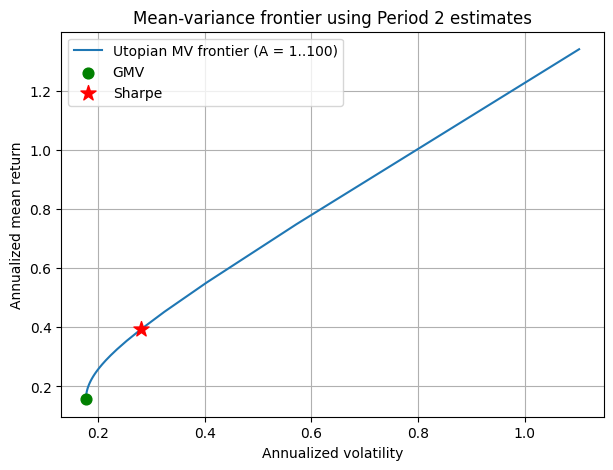

In [ ]:
def port_stats(w, mu, sigma):
    w = np.asarray(w)
    return w @ mu, np.sqrt(w @ sigma @ w)

mu2v, cov2v = mu2.values, cov2.values

#Utopian Frontier on the A grid
W5 = np.array([mv_port(A, mu2v, cov2v) for A in A_grid])
mean5 = W5 @ mu2v
vol5 = np.sqrt(np.einsum('ij,jk,ik->i', W5, cov2v, W5))

#GMV and Sharpe (tangency) portfolios, computed exactly
mean_gmv, vol_gmv = port_stats(w0_2, mu2v, cov2v)
A_T = np.ones(3) @ np.linalg.inv(cov2v) @ mu2v
w_T = mv_port(A_T, mu2v, cov2v)
mean_T, vol_T = port_stats(w_T, mu2v, cov2v)
print("A_T=", A_T, " | Sharpe weights:", w_T.round(4), "| Sum:", w_T.sum().round(8))

#Plot (annualized: mean x12, vol x sqrt(12), applied to every series)
k_m, k_v = 12, np.sqrt(12)
plt.figure(figsize=(7, 5))
plt.figure(figsize=(7, 5))
plt.plot(vol5*k_v, mean5*k_m, label="Utopian MV frontier (A = 1..100)")
plt.scatter(vol_gmv*k_v, mean_gmv*k_m, color="green", s=60, zorder=3, label="GMV")
plt.scatter(vol_T*k_v, mean_T*k_m, color="red", marker="*", s=130, zorder=3, label="Sharpe")
plt.xlabel("Annualized volatility"); plt.ylabel("Annualized mean return")
plt.title("Mean-variance frontier using Period 2 estimates")
plt.grid(True); plt.legend()
plt.show() 
    

#### 6. Realistic Out-of-Sample Evaluation

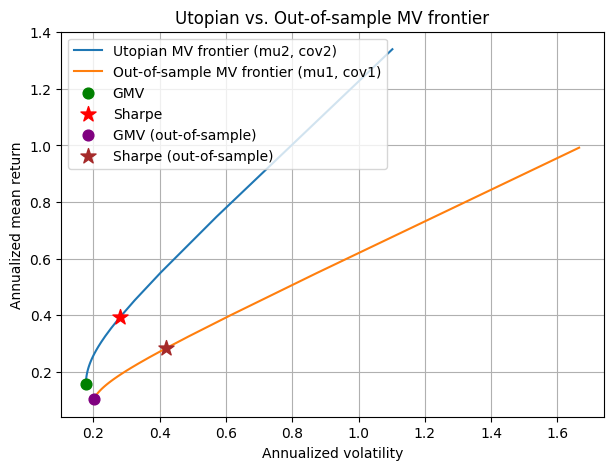

In [ ]:
mu1v, cov1v = mu1.values, cov1.values

#build portfolios with period 1 estimates, evaluate them with period 2 estimates
W6 = np.array([mv_port(A, mu1v, cov1v) for A in A_grid])
mean6 = W6 @ mu2v
vol6 = np.sqrt(np.einsum('ij,jk,ik->i', W6, cov2v, W6))

#period-1 GMV and Sharpe portfolios, evaluated with period 2 estimates
mean_gmv1, vol_gmv1 = port_stats(w0_1, mu2v, cov2v)
A_T1 = np.ones(3) @ np.linalg.inv(cov1v) @ mu1v
w_T1 = mv_port(A_T1, mu1v, cov1v)
mean_T1, vol_T1 = port_stats(w_T1, mu2v, cov2v)

plt.figure(figsize=(7, 5))
plt.plot(vol5 * k_v, mean5 * k_m, color="tab:blue", label="Utopian MV frontier (mu2, cov2)")
plt.plot(vol6 * k_v, mean6 * k_m, color="tab:orange", label="Out-of-sample MV frontier (mu1, cov1)")
plt.scatter(vol_gmv*k_v, mean_gmv*k_m, color="green", s=60, zorder=3, label="GMV")
plt.scatter(vol_T*k_v, mean_T*k_m, color="red", marker="*", s=130, zorder=3, label="Sharpe")
plt.scatter(vol_gmv1*k_v, mean_gmv1*k_m, color="purple", s=60, zorder=3, label="GMV (out-of-sample)")
plt.scatter(vol_T1*k_v, mean_T1*k_m, color="brown", marker="*", s=130, zorder=3, label="Sharpe (out-of-sample)")
plt.xlabel("Annualized volatility"); plt.ylabel("Annualized mean return")
plt.title("Utopian vs. Out-of-sample MV frontier")
plt.grid(True); plt.legend()
plt.show()

#### 7. Comparison of Utopian MV vs. Out-of-Sample MV

In [ ]:
inv2 = np.linalg.inv(cov2v); one = np.ones(3)
a, b, c = one @ inv2 @ one, one @ inv2 @ mu2v, mu2v @ inv2 @ mu2v
minvar = lambda mu: (a*mu**2 - 2*b*mu + c) / (a*mu**2 - 2*b*mu + c)

gap = vol6 - np.sqrt(minvar(mean6))
print("min gap (should be >= 0):", gap.min(), "| max gap:", gap.max())

min gap (should be >= 0): -0.9407748885296257 | max gap: -0.5191434539139805


#### 8. Parsimonious Build

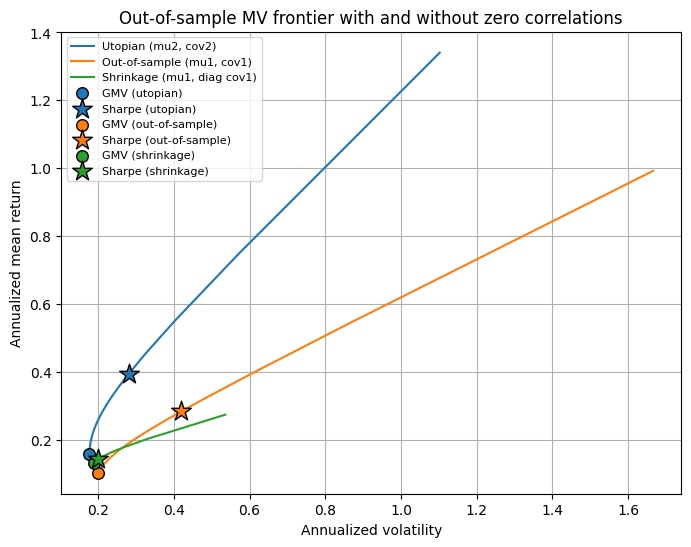

Vol 0.25: Utopian 0.1687 | Out-of-sample 0.1115 | Shrinkage 0.1325
Vol 0.30: Utopian 0.1687 | Out-of-sample 0.1115 | Shrinkage 0.1325
Vol 0.40: Utopian 0.1687 | Out-of-sample 0.1115 | Shrinkage 0.1325
Vol 0.50: Utopian 0.1687 | Out-of-sample 0.1115 | Shrinkage 0.1325


,Ann. mean,Ann. vol,Ann. Sharpe
GMV (utopian),0.1568,0.1773,0.8845
Sharpe (utopian),0.3941,0.2811,1.4020
GMV (out-of-sample),0.1026,0.2010,0.5104
Sharpe (out-of-sample),0.2833,0.4198,0.6749
GMV (shrinkage),0.1311,0.1880,0.6971
Sharpe (shrinkage),0.1428,0.2010,0.7104


In [72]:
mu1v, cov1v = mu1.values, cov1.values
cov1_diag = np.diag(np.diag(cov1v))  # zero correlations

def frontier(A_grid, mu_est, S_est, mu_eval, S_eval):
    W = np.array([mv_port(A, mu_est, S_est) for A in A_grid])
    return W @ mu_eval, np.sqrt(np.einsum("ij,jk,ik->i", W, S_eval, W))

mean6, vol6 = frontier(A_grid, mu1v, cov1v, mu2v, cov2v)       # Part 6 (out-of-sample)
mean8, vol8 = frontier(A_grid, mu1v, cov1_diag, mu2v, cov2v)   # Part 8 (shrinkage)

# GMV and Sharpe portfolios for each set of estimates, all evaluated in period 2
def gmv_and_sharpe(mu_est, S_est):
    w0, _ = two_funds(mu_est, S_est)
    A_T = np.ones(3) @ np.linalg.inv(S_est) @ mu_est
    wT = mv_port(A_T, mu_est, S_est)
    return port_stats(w0, mu2v, cov2v), port_stats(wT, mu2v, cov2v)

(m_g1, v_g1), (m_T1, v_T1) = gmv_and_sharpe(mu1v, cov1v)
(m_gd, v_gd), (m_Td, v_Td) = gmv_and_sharpe(mu1v, cov1_diag)

plt.figure(figsize=(8, 6))
plt.plot(vol5 * k_v, mean5 * k_m, color="tab:blue", label="Utopian (mu2, cov2)")
plt.plot(vol6 * k_v, mean6 * k_m, color="tab:orange", label="Out-of-sample (mu1, cov1)")
plt.plot(vol8 * k_v, mean8 * k_m, color="tab:green", label="Shrinkage (mu1, diag cov1)")

plt.scatter(vol_gmv * k_v, mean_gmv * k_m, color="tab:blue", edgecolors="black", s=70, zorder=3, label="GMV (utopian)")
plt.scatter(vol_T * k_v, mean_T * k_m, color="tab:blue", edgecolors="black", marker="*", s=220, zorder=3, label="Sharpe (utopian)")
plt.scatter(v_g1 * k_v, m_g1 * k_m, color="tab:orange", edgecolors="black", s=70, zorder=3, label="GMV (out-of-sample)")
plt.scatter(v_T1 * k_v, m_T1 * k_m, color="tab:orange", edgecolors="black", marker="*", s=220, zorder=3, label="Sharpe (out-of-sample)")
plt.scatter(v_gd * k_v, m_gd * k_m, color="tab:green", edgecolors="black", s=70, zorder=3, label="GMV (shrinkage)")
plt.scatter(v_Td * k_v, m_Td * k_m, color="tab:green", edgecolors="black", marker="*", s=220, zorder=3, label="Sharpe (shrinkage)")

plt.xlabel("Annualized volatility"); plt.ylabel("Annualized mean return")
plt.title("Out-of-sample MV frontier with and without zero correlations")
plt.grid(True); plt.legend(fontsize=8)
plt.show()

# mean return of each frontier at the same volatility levels (annualized)
for v in [0.25, 0.30, 0.40, 0.50]:
    m_u = np.interp(v, vol5 * k_v, mean5 * k_m)
    m_6 = np.interp(v, vol6 * k_v, mean6 * k_m)
    m_8 = np.interp(v, vol8 * k_v, mean8 * k_m)
    print(f"Vol {v:.2f}: Utopian {m_u:.4f} | Out-of-sample {m_6:.4f} | Shrinkage {m_8:.4f}")

# GMV and Sharpe summary (evaluated in period 2, annualized)
pd.DataFrame({
    "Ann. mean": [mean_gmv, mean_T, m_g1, m_T1, m_gd, m_Td],
    "Ann. vol":  [vol_gmv, vol_T, v_g1, v_T1, v_gd, v_Td],
}, index=["GMV (utopian)", "Sharpe (utopian)", "GMV (out-of-sample)", "Sharpe (out-of-sample)",
          "GMV (shrinkage)", "Sharpe (shrinkage)"]).mul([k_m, k_v]).assign(
    **{"Ann. Sharpe": lambda d: d["Ann. mean"] / d["Ann. vol"]}).round(4)
